In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from recover.constants import DATA_DIR

In [3]:
from recover.dataset import RasterDataset, raster_to_df
from recover.visualise import plot_cell_over_time, plot_single_band, set_plot_defaults

set_plot_defaults()

# Read raw data

In [26]:
luh = pd.read_parquet(DATA_DIR / 'luh_timeseries.parquet')
luh = luh.fillna(0.0)

esa = pd.read_parquet(DATA_DIR / 'esa_timeseries.parquet')

# Preprocess

In [77]:
esa_ds = RasterDataset(esa)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']
Finished building array with shape (31, 15, 157, 180)


## Join tabular and biome data

In [5]:
biomes = raster_to_df(DATA_DIR / 'NTAmericas_efgs_50km.tif')
biomes

DATA SHAPE: (1, 157, 180)
METADATA:
{'count': 1,
 'crs': CRS.from_wkt('PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",-5],PARAMETER["longitude_of_center",-65],PARAMETER["standard_parallel_1",10],PARAMETER["standard_parallel_2",-20],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]'),
 'driver': 'GTiff',
 'dtype': 'uint8',
 'height': 157,
 'nodata': 255.0,
 'transform': Affine(50000.0, 0.0, -5516832.203866814,
       0.0, -50000.0, 3706678.156476609),
 'width': 180}


,NTAmericas_efgs_50km
cell,
11,11
12,11
13,11
188,16
189,16
...,...
28012,7
28187,7
28188,7


In [6]:
biome_classes = pd.read_excel(DATA_DIR / 'ESA-LC_Biome_proportions.xlsx')[['our_efg', 'Biome_Classes']].rename(columns={'Biome_Classes': 'biome_classes'})
biome_classes.index = biome_classes.index + 1
display(biome_classes)

biomes = biomes.join(biome_classes, how='left', on='NTAmericas_efgs_50km')
biomes

,our_efg,biome_classes
1,Cool deserts and semi-deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
2,Hyper-arid deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
3,Intertidal forests and shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Mangrov...
4,Oceanic cool temperate rainforests,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
5,Pyric tussock savannas,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
6,Seasonal floodplain marshes,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
8,Seasonally dry tropical shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
9,Temperate alpine grasslands and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
10,Temperate subhumid grasslands,ESA_Forest_Bl_Ev|ESA_Shrubland


,NTAmericas_efgs_50km,our_efg,biome_classes
cell,,,
11,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
12,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
13,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
188,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
189,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
...,...,...,...
28012,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28187,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28188,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation


In [7]:
def compute_habitat_fraction(esa_df, biomes_df):
    df = esa_df.join(biomes_df, how='left', on='cell')
    out = pd.Series(index=df.index)
    for biome, data in df.groupby('our_efg'):
        print('---', biome, '---')
        cols = data['biome_classes'].iloc[0].split('|')
        habitat_fraction = data[cols].sum(axis=1).rename('habitat')
        out.loc[data.index] = habitat_fraction
        print(data[cols].mean(), '\n')
        print(habitat_fraction.describe(), '\n')

    return out

esa_with_hab = esa.copy()
esa_with_hab['habitat'] = compute_habitat_fraction(esa, biomes)

--- Cool deserts and semi-deserts ---
ESA_BareAreas           0.013850
ESA_Shrubland           0.527584
ESA_SparseVegetation    0.432413
dtype: float64 

count    1178.000000
mean        0.973847
std         0.049435
min         0.750767
25%         0.973749
50%         0.995088
75%         0.999113
max         1.000000
Name: habitat, dtype: float64 

--- Hyper-arid deserts ---
ESA_BareAreas           0.522571
ESA_Shrubland           0.121442
ESA_SparseVegetation    0.198175
dtype: float64 

count    4805.000000
mean        0.842189
std         0.208288
min         0.000000
25%         0.784572
50%         0.928775
75%         0.988925
max         1.000000
Name: habitat, dtype: float64 

--- Intertidal forests and shrublands ---
ESA_Forest_Bl_Dec    0.010493
ESA_Forest_Bl_Ev     0.255790
ESA_Mangrove         0.163826
ESA_Shrubland        0.073343
ESA_Varzea           0.023471
dtype: float64 

count    4960.000000
mean        0.526923
std         0.238779
min         0.000000
25%       

In [8]:

esa_hab_ds = RasterDataset(esa_with_hab)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']
Finished building array with shape (31, 15, 157, 180)
Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water', 'habitat']
Finished building array with shape (31, 16, 157, 180)


## Fill missing LUH data (non-land)

In [9]:
luh_ds = RasterDataset(luh)
luh['water'] = (1.0 - luh[luh_ds.bands].sum(axis=1))
luh_ds = RasterDataset(luh)
luh.isna().sum()
luh_ds.data.isna().sum()

Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']
Finished building array with shape (130, 8, 157, 180)
Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops', 'water']
Finished building array with shape (130, 9, 157, 180)


pastr    0
primf    0
primn    0
range    0
secdf    0
secdn    0
urban    0
crops    0
year     0
water    0
dtype: int64

In [10]:
luh_ds.data.isna().sum()

pastr    0
primf    0
primn    0
range    0
secdf    0
secdn    0
urban    0
crops    0
year     0
water    0
dtype: int64

# Visualise

## Single cell over time

NameError: name 'esa_ds' is not defined

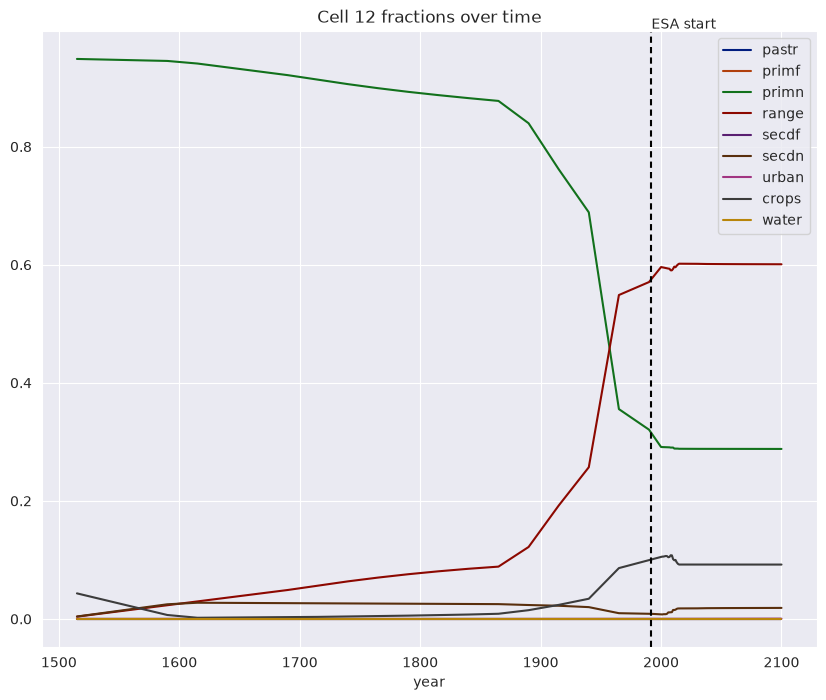

In [11]:
set_plot_defaults()
plot_cell_over_time(luh_ds, cell_id=12)
plt.axvline(1992, color='k', dashes=(3, 2))
plt.text(1992, 1.0, 'ESA start')

plot_cell_over_time(esa_ds, cell_id=12)

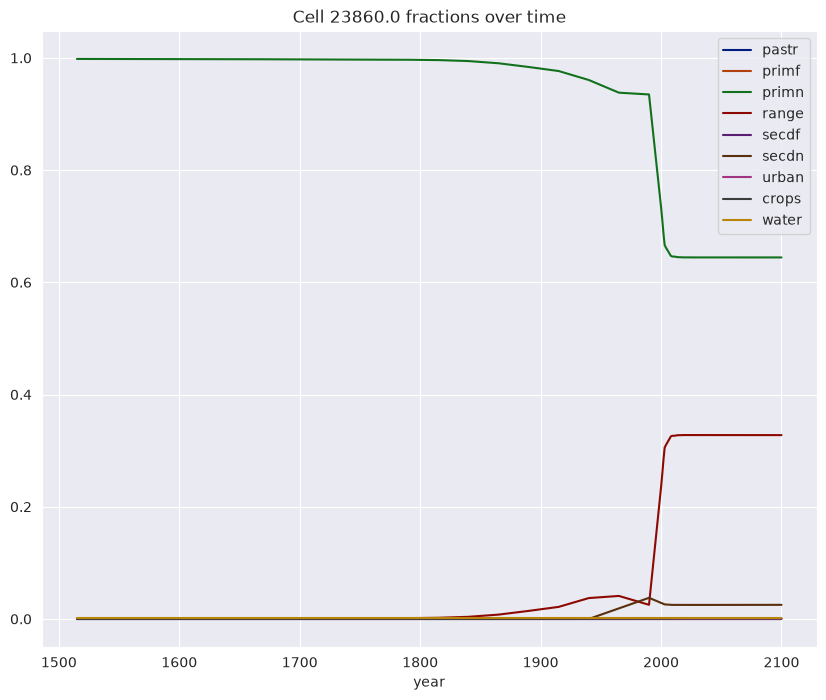

In [22]:
plot_cell_over_time(luh_ds);

<Axes: title={'center': 'Per biome habitat fraction over time'}, xlabel='year'>

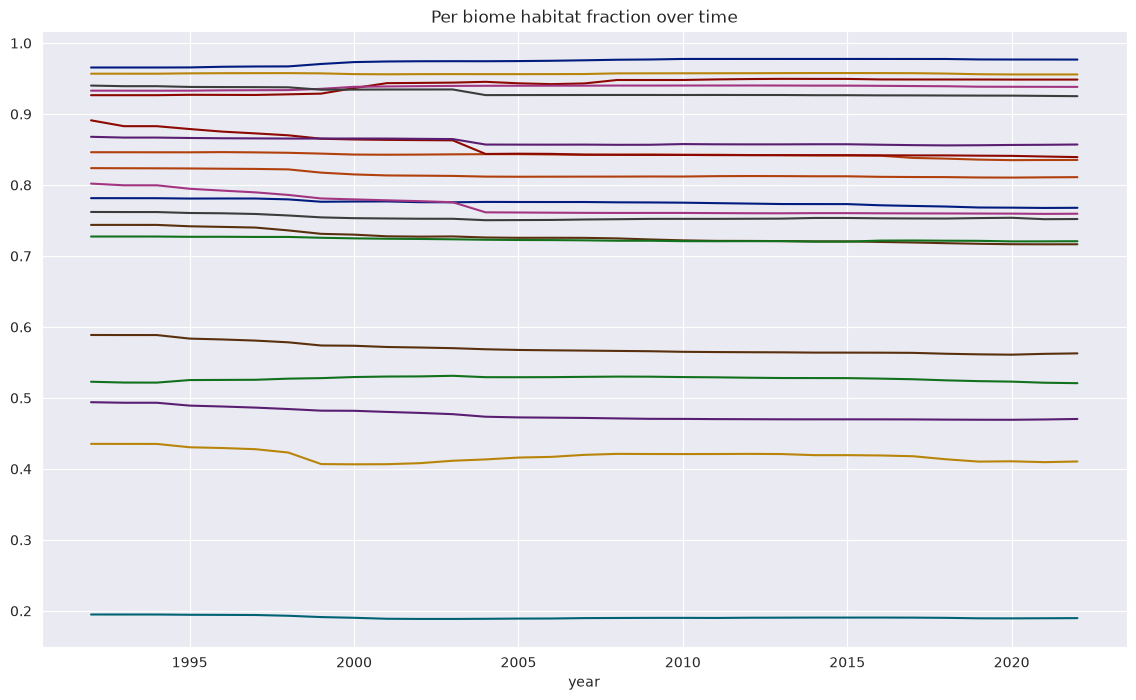

In [23]:
habitat_over_time = (
    esa_hab_ds.data.join(biomes)
    .set_index(esa_hab_ds.time_col)
    .groupby(['our_efg', esa_hab_ds.time_col])
    ['habitat']
    .mean()
    .unstack()
    .T
)

habitat_over_time.plot(legend=False, title='Per biome habitat fraction over time', figsize=(14, 8))

# Evaluation per time slice

In [28]:
common_years = sorted(list(set(luh['year']).intersection(set(esa['year']))))
common_years

[1992.0,
 1993.0,
 1994.0,
 1995.0,
 1996.0,
 1997.0,
 1998.0,
 1999.0,
 2000.0,
 2001.0,
 2002.0,
 2003.0,
 2004.0,
 2005.0,
 2006.0,
 2007.0,
 2008.0,
 2009.0,
 2010.0,
 2011.0,
 2012.0,
 2013.0,
 2014.0,
 2015.0,
 2016.0,
 2017.0,
 2018.0,
 2019.0,
 2020.0,
 2021.0,
 2022.0]

In [59]:
from recover.evaluation import evaluate
from recover.models.linear import MultiOutputOLS, SimplexRegression
import time
from tqdm import tqdm

def get_stepped_folds(common_years: list, train_window: int = 15, test_window: int = 5):
    for fold in range(len(common_years) - (train_window + test_window) + 1):
        test_start = fold
        train_start = fold + test_window
        train_end = train_start + train_window

        test_years = common_years[test_start:train_start]
        train_years = common_years[train_start:train_end]
        yield train_years, test_years

models = {
    'simplex': SimplexRegression,
    'ols': MultiOutputOLS,
}

results = []
for model_name, model_cls in models.items():
    for fold_id, (train_years, test_years) in tqdm(enumerate(get_stepped_folds(common_years))):
        X_train = luh_ds.get_time_slice(train_years)
        y_train = esa_ds.get_time_slice(train_years)
        X_test = luh_ds.get_time_slice(test_years)
        y_test = esa_ds.get_time_slice(test_years)

        model = model_cls()
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        t1 = time.perf_counter()
        y_pred = model.predict(X_test)
        fold_eval = evaluate(y_test, y_pred, name=f'{model_name}')
        fold_eval['fold_id'] = fold_id
        fold_eval['fit_time_seconds'] = t1 - t0
        results.append(fold_eval)
    
    display(pd.concat(results, axis=1).T)
    

0it [00:00, ?it/s]

12it [08:59, 44.96s/it]


,kl_divergence,js_divergence,mean_absolute_error,fold_id,fit_time_seconds
simplex,0.593591,0.147253,0.049337,0.0,51.339084
simplex,0.593020,0.147088,0.049305,1.0,50.221098
simplex,0.591657,0.146767,0.049245,2.0,47.410169
simplex,0.590463,0.146777,0.049273,3.0,53.637709
simplex,0.588953,0.146449,0.049211,4.0,44.620145
simplex,0.587414,0.146084,0.049134,5.0,43.197874
simplex,0.586455,0.145938,0.049106,6.0,43.299612
simplex,0.585775,0.145709,0.049058,7.0,43.667745
simplex,0.586340,0.145722,0.049049,8.0,39.796374
simplex,0.586776,0.145729,0.049042,9.0,32.796441


12it [00:48,  4.05s/it]


,kl_divergence,js_divergence,mean_absolute_error,fold_id,fit_time_seconds
simplex,0.593591,0.147253,0.049337,0.0,51.339084
simplex,0.593020,0.147088,0.049305,1.0,50.221098
simplex,0.591657,0.146767,0.049245,2.0,47.410169
simplex,0.590463,0.146777,0.049273,3.0,53.637709
simplex,0.588953,0.146449,0.049211,4.0,44.620145
simplex,0.587414,0.146084,0.049134,5.0,43.197874
simplex,0.586455,0.145938,0.049106,6.0,43.299612
simplex,0.585775,0.145709,0.049058,7.0,43.667745
simplex,0.586340,0.145722,0.049049,8.0,39.796374
simplex,0.586776,0.145729,0.049042,9.0,32.796441


## Single training, multiple test windows

In [60]:
results_gap = []
for model_name, model_cls in models.items():
    # Single training set and fitted model
    train_years, _ = list(get_stepped_folds(common_years))[-1]
    X_train = luh_ds.get_time_slice(train_years)
    y_train = esa_ds.get_time_slice(train_years)
    print(f'Training {model_name} with years {train_years}')
    model = model_cls()
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t1 = time.perf_counter()

    for _, test_years in get_stepped_folds(common_years):
        X_test = luh_ds.get_time_slice(test_years)
        y_test = esa_ds.get_time_slice(test_years)

        y_pred = model.predict(X_test)
        fold_eval = evaluate(y_test, y_pred, name=f'{model_name}')
        fold_eval['test_start'] = test_years[0]
        fold_eval['test_end'] = test_years[-1]
        fold_eval['fit_time_seconds'] = t1 - t0
        results_gap.append(fold_eval)
    
pd.concat(results_gap, axis=1).T

Training simplex with years [2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0, 2020.0, 2021.0, 2022.0]
Training ols with years [2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0, 2020.0, 2021.0, 2022.0]


,kl_divergence,js_divergence,mean_absolute_error,test_start,test_end,fit_time_seconds
simplex,0.589027,0.146919,0.049322,1992.0,1996.0,42.570251
simplex,0.588306,0.146664,0.049263,1993.0,1997.0,42.570251
simplex,0.587644,0.146412,0.049201,1994.0,1998.0,42.570251
simplex,0.587084,0.146149,0.049138,1995.0,1999.0,42.570251
simplex,0.586543,0.145877,0.049072,1996.0,2000.0,42.570251
simplex,0.586001,0.145622,0.049007,1997.0,2001.0,42.570251
simplex,0.585724,0.145451,0.048961,1998.0,2002.0,42.570251
simplex,0.585646,0.145342,0.048927,1999.0,2003.0,42.570251
simplex,0.586267,0.145344,0.048924,2000.0,2004.0,42.570251
simplex,0.586978,0.145405,0.048936,2001.0,2005.0,42.570251


In [83]:
y_test_gif = esa_ds.get_time_slice(list(range(1992, 2008)), return_year=True)

pred_df = pd.DataFrame(model.predict(y_test_gif.drop('year', axis=1)), index=y_test_gif.index, columns=y_test_gif.columns)
pred_df['year'] = y_test_gif['year']
pred_df

,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water,year
cell,,,,,,,,,,,,,,,,
11.0,6.425054e-02,0.218984,0.063969,9.791974e-13,1.952322e-02,0.026998,0.102643,0.010187,4.084843e-04,0.399408,1.010208e-03,0.081506,4.821005e-04,1.082628e-03,0.009548,2003.0
12.0,6.214527e-02,0.238879,0.065781,9.786964e-13,1.996287e-02,0.026951,0.099533,0.009803,9.786964e-13,0.390930,9.657075e-04,0.078737,2.206216e-04,7.853333e-04,0.005307,2003.0
13.0,6.290319e-02,0.258334,0.077147,1.593923e-03,2.254357e-02,0.026085,0.090646,0.008915,9.993977e-13,0.370725,9.193922e-04,0.074248,8.585430e-05,9.336988e-04,0.004921,2003.0
188.0,4.756536e-02,0.462693,0.073364,9.984612e-13,2.296445e-02,0.025772,0.051491,0.004820,9.984612e-13,0.261610,5.169753e-04,0.044341,1.132876e-04,4.270038e-04,0.004320,2003.0
189.0,4.714717e-02,0.480123,0.077287,6.539652e-03,2.406351e-02,0.025212,0.044630,0.004160,9.999294e-13,0.245168,4.830732e-04,0.040559,7.103739e-05,4.816533e-04,0.004074,2003.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28012.0,5.129836e-02,0.083832,0.004206,2.162115e-01,9.899443e-13,0.018957,0.076754,0.007241,7.010923e-02,0.146998,9.899443e-13,0.038792,1.385533e-02,1.412057e-02,0.257625,2007.0
28187.0,9.806637e-13,0.080962,0.059598,1.079745e-01,9.806637e-13,0.029160,0.196490,0.014687,9.806637e-13,0.427681,9.806637e-13,0.072981,9.806637e-13,9.806637e-13,0.010466,2007.0
28188.0,9.823540e-13,0.083799,0.054945,9.771675e-02,9.823540e-13,0.029680,0.197734,0.014906,9.823540e-13,0.433820,9.823540e-13,0.074512,9.823540e-13,9.823540e-13,0.012888,2007.0


In [85]:
pred_ds = RasterDataset(pred_df)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']
Finished building array with shape (5, 15, 157, 180)


In [86]:
from recover.visualise import animate_band
animate_band(esa_ds, 'ESA_Forest_Bl_Ev', DATA_DIR / 'esa_test.gif')
animate_band(pred_ds, 'ESA_Forest_Bl_Ev', DATA_DIR / 'pred_test.gif')


animate_band(luh_ds, 'primf', DATA_DIR / 'luh_test.gif')

In [62]:
# ds = RasterDataset(esa_with_hab[['year', 'cell', 'habitat']])

# plot_single_band(ds.arr[0, 0, :, :], cmap='viridis')
# plt.colorbar();